# Exploratory Data Analysis
### 1. Dataset Overview

The Online Retail II dataset contains historical transaction records from a UK-based online retailer. Each row represents an individual transaction line, including invoice, product, quantity, price, customer, and geographic information.

The following exploration examines the dataset's structure, completeness, and characteristics before data preparation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Dejavu Sans'
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', None)

In [3]:
PROJECT_ROOT = Path.cwd().parents[0]

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw_online_retail_II.csv"

In [4]:
df = pd.read_csv(RAW_DATA_PATH)

print(f"[+] Loaded Dataset shape: {df.shape[0]:,} rows and {df.shape[1]} columns")

[+] Loaded Dataset shape: 525,461 rows and 8 columns


In [5]:
df.head(5)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


### 2. Structural and Missing-Value Analysis

In [6]:
print("="*50)
print("\tSTRUCTURAL DATA TYPES & NULLS")
print("="*50)
df.info()

	STRUCTURAL DATA TYPES & NULLS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      525461 non-null  object 
 1   StockCode    525461 non-null  object 
 2   Description  522533 non-null  object 
 3   Quantity     525461 non-null  int64  
 4   InvoiceDate  525461 non-null  object 
 5   Price        525461 non-null  float64
 6   Customer ID  417534 non-null  float64
 7   Country      525461 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.1+ MB


In [7]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})

missing_summary

,Missing Values,Missing %
Invoice,0,0.00
StockCode,0,0.00
Description,2928,0.56
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,107927,20.54
Country,0,0.00


### 2.2 Numerical Summary

In [8]:
print("="*50)
print("\tSUMMARY STATISTICS")
print("="*50)
display(df[['Quantity', 'Price']].describe().T)

	SUMMARY STATISTICS


,count,mean,std,min,25%,50%,75%,max
Quantity,525461.0,10.337667,107.424110,-9600.00,1.00,3.0,10.00,19152.00
Price,525461.0,4.688834,146.126914,-53594.36,1.25,2.1,4.21,25111.09


### 3. Business Data Dictionary

In [62]:
# Business Definitions for Each Column
# The Below dictionary has the following format
# |Label|Units|Definition|
business_definitions = {
    "Invoice": ("Invoice Number", "ID", "Invoice Number transaction identifier (6-7 characters). Starts with '4' or '5' for standard sales, 'C' for cancellations, and 'A' for administrative adjustments. Multiple transaction lines can share one invoice"),
    "StockCode": ("Stock Code", "SKU", "Product or administrative item code. Primarily 5-digit numeric SKUs, alongside operational/shipping codes (e.g., 'POST', 'DOT') and discount flags."),
    "Description": ("Product Description", "Text", "Descriptive name for products, operational fees, or vouchers. Contains historical missing values and warehouse logging noise."),
    "Quantity": ("Quantity Sold", "Count", "Number of units ordered per transaction line. Negative values indicate product returns or reversals."),
    "InvoiceDate": ("Invoice Timestamp", "Datetime", "Exact date and time when the transaction was generated."),
    "Price": ("Unit Price", "GBP (£)", "Product price per unit stated in British Pounds Sterling."),
    "Customer ID": ("Customer ID", "ID", "Unique 5-digit customer identifier. Contains 107,927 missing entries."),
    "Country": ("Country", "Text", "Geographic region where the transaction or customer is located (40 unique countries).")
}

In [63]:
# |Feature Name|Business Label|Data Type|unit|Null count|Unique values|Description|
dict_list = []

for col in df.columns:
    label, unit, definition = business_definitions.get(col, (col, "N/A", "No Definition"))
    dict_list.append({
        "Feature Name": col,
        "Business Label": label,
        "Data Type": str(df[col].dtype),
        "Unit": unit,
        "Null Count": df[col].isnull().sum(),
        "Unique Values": df[col].nunique(),
        "Description": definition
    })

dict_df = pd.DataFrame(dict_list)
display(dict_df)

,Feature Name,Business Label,Data Type,Unit,Null Count,Unique Values,Description
0,Invoice,Invoice Number,object,ID,0,28816,Invoice Number transaction identifier (6-7 cha...
1,StockCode,Stock Code,object,SKU,0,4632,Product or administrative item code. Primarily...
2,Description,Product Description,object,Text,2928,4681,"Descriptive name for products, operational fee..."
3,Quantity,Quantity Sold,int64,Count,0,825,Number of units ordered per transaction line. ...
4,InvoiceDate,Invoice Timestamp,datetime64[ns],Datetime,0,25296,Exact date and time when the transaction was g...
5,Price,Unit Price,float64,GBP (£),0,1606,Product price per unit stated in British Pound...
6,Customer ID,Customer ID,float64,ID,107927,4383,Unique 5-digit customer identifier. Contains 1...
7,Country,Country,object,Text,0,40,Geographic region where the transaction or cus...


In [64]:
REPORTS_DIR_PATH = PROJECT_ROOT / "reports"
DICTIONARY_PATH = REPORTS_DIR_PATH / "DataDictionary.csv"
REPORTS_DIR_PATH.mkdir(parents=True, exist_ok=True)

dict_df.to_csv(DICTIONARY_PATH, index=False)
print(f"\n[+]Exported Business Data Dictionary artifact to: {DICTIONARY_PATH}")


[+]Exported Business Data Dictionary artifact to: s:\Projects\online-retail-ii\reports\DataDictionary.csv


### 4. Invoice & Transaction analysis

The Invoice ID starts with 4 or 5; if it starts with a C its a cancelled order, and if it starts with an A it signifies adminstrative adjustments.

In [65]:
invoice_prefix = df['Invoice'].str[0]

invoice_summary = pd.DataFrame({
    "Record Count": invoice_prefix.value_counts(),
    "Percentage": (invoice_prefix.value_counts(normalize=True) * 100).round(2)
    })

display(invoice_summary)

print(f"Total transaction records: {len(df):,}")
print(f"Unique invoices: {df['Invoice'].nunique():,}")

,Record Count,Percentage
Invoice,,
5,406763,77.41
4,108489,20.65
C,10206,1.94
A,3,0.00


Total transaction records: 525,461
Unique invoices: 28,816


In [13]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f"Earliest transaction: {df['InvoiceDate'].min()}")
print(f"Latest transaction:   {df['InvoiceDate'].max()}")

Earliest transaction: 2009-12-01 07:45:00
Latest transaction:   2010-12-09 20:01:00


In [14]:
transaction_summary = df.assign(
    InvoicePrefix=invoice_prefix,
    NegativeQuantity=df["Quantity"] < 0,
    ZeroQuantity=df["Quantity"] == 0,
    NegativePrice=df["Price"] < 0,
    ZeroPrice=df["Price"] == 0
).groupby("InvoicePrefix").agg(
    Records=("Invoice", "size"),
    NegativeQuantity=("NegativeQuantity", "sum"),
    ZeroQuantity=("ZeroQuantity", "sum"),
    NegativePrice=("NegativePrice", "sum"),
    ZeroPrice=("ZeroPrice", "sum")
)

display(transaction_summary)

,Records,NegativeQuantity,ZeroQuantity,NegativePrice,ZeroPrice
InvoicePrefix,,,,,
4,108489,729,0,0,1108
5,406763,1392,0,0,2579
A,3,0,0,3,0
C,10206,10205,0,0,0


In [15]:
adjustment_records = df[invoice_prefix == 'A']
display(adjustment_records)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


In [16]:
cancellation_positive = df[
    (invoice_prefix == "C") & (df["Quantity"] > 0)
]

display(cancellation_positive)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom


**Key Findings**

The dataset contains 525,461 transaction records associated with 28,816 unique invoice identifiers. The majority of records belong to invoices beginning with prefix `5` (77.41%), followed by prefix `4` (20.65%). Cancellation-prefixed invoices (`C`) account for 1.94% of the records, while only three administrative adjustment records (`A`) were identified.

Further investigation shows that all three administrative adjustment records contain negative prices and positive quantities. Among the 10,206 cancellation-prefixed records, 10,205 have negative quantities, while one record has a positive quantity. Additionally, 2,121 records under standard invoice prefixes `4` and `5` also contain negative quantities.

These findings indicate that invoice prefixes provide useful transaction classifications, but transaction signs alone do not fully determine the nature of a record. Cancellation, return, and adjustment records therefore require separate consideration during data preparation rather than automatic exclusion based solely on quantity or invoice prefix.

The transaction timestamps span from December 1, 2009, to December 9, 2010, covering slightly more than one year of retail activity.

In [17]:
REPORTS_DIR_PATH = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORTS_DIR_PATH / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

### 5. Quantity and Price Analysis

#### 5.1 Quantity distribution

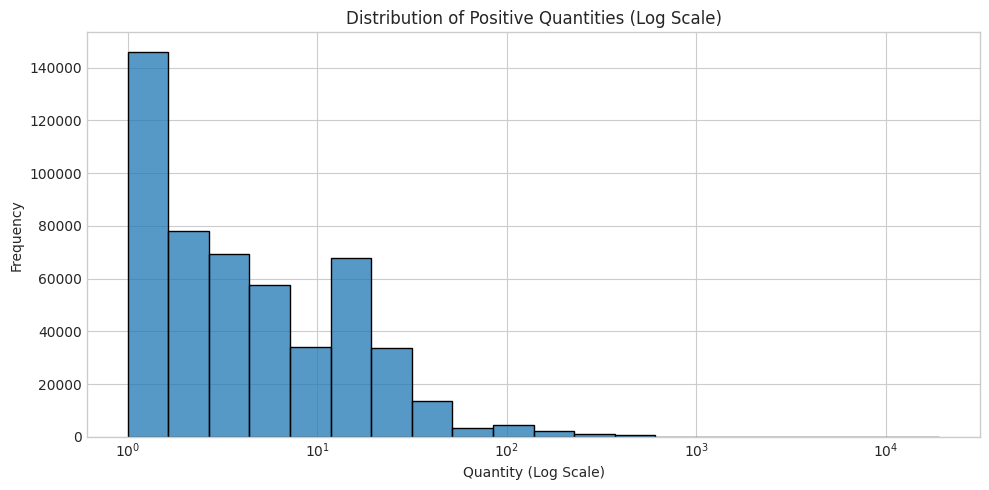

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['Quantity'] > 0],
    x='Quantity',
    bins=20,
    kde=False,
    log_scale=True
)

plt.title('Distribution of Positive Quantities (Log Scale)')
plt.xlabel('Quantity (Log Scale)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'positive_quantity_distr.png', dpi=300, bbox_inches='tight')
plt.show()

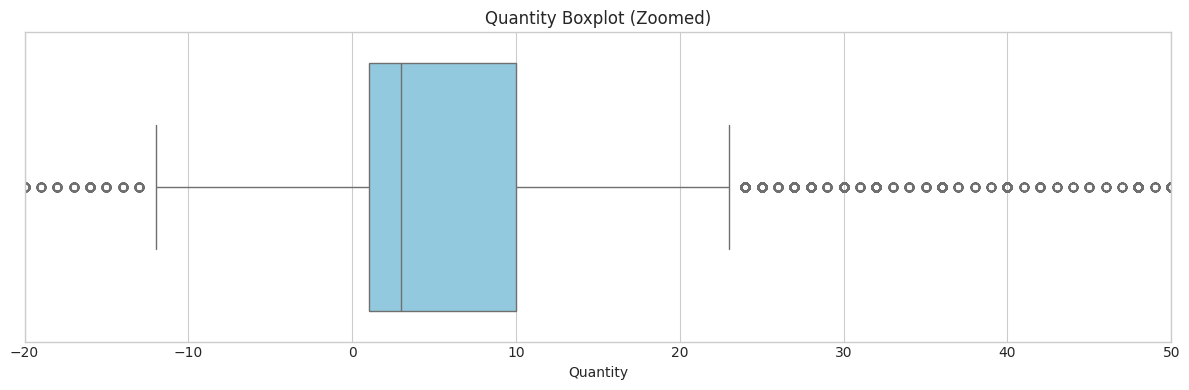

In [19]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    data=df,
    x='Quantity',
    color='skyblue'
)

plt.xlim(-20, 50)

plt.title('Quantity Boxplot (Zoomed)')
plt.xlabel('Quantity')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'quantity_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

The quantity distribution is heavily right-skewed, with most transaction lines concentrated at relatively low quantities. The histogram uses a logarithmic x-axis to make the long right tail easier to examine.

The highest frequency occurs at a quantity of one, indicating that single-unit transaction lines are common. The distribution also contains a small number of exceptionally large quantities, including values approaching 19,152 units.

The boxplot provides a closer view of the central distribution. The median quantity is 3 units, while the interquartile range extends from 1 to 10 units. Values beyond the whiskers are classified as statistical outliers, highlighting substantial variation in transaction quantities.

**Key observations:**
- Most transaction lines contain relatively small quantities.
- The distribution has a pronounced right tail.
- Extreme quantities warrant further investigation before any cleaning or exclusion decisions.

#### 5.2 Price Distribution

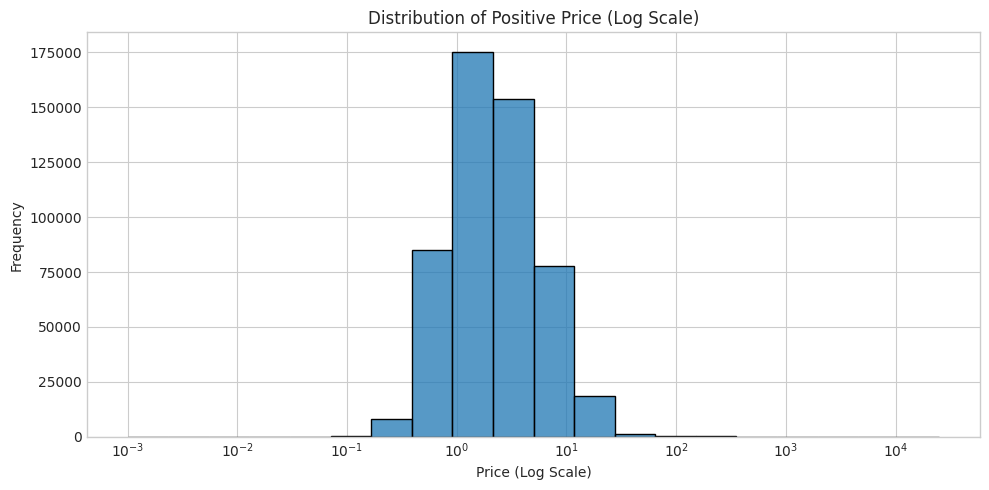

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['Price'] > 0],
    x='Price',
    bins=20,
    kde=False,
    log_scale=True
)

plt.title('Distribution of Positive Price (Log Scale)')
plt.xlabel('Price (Log Scale)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'positive_price_distr.png', dpi=300, bbox_inches='tight')
plt.show()

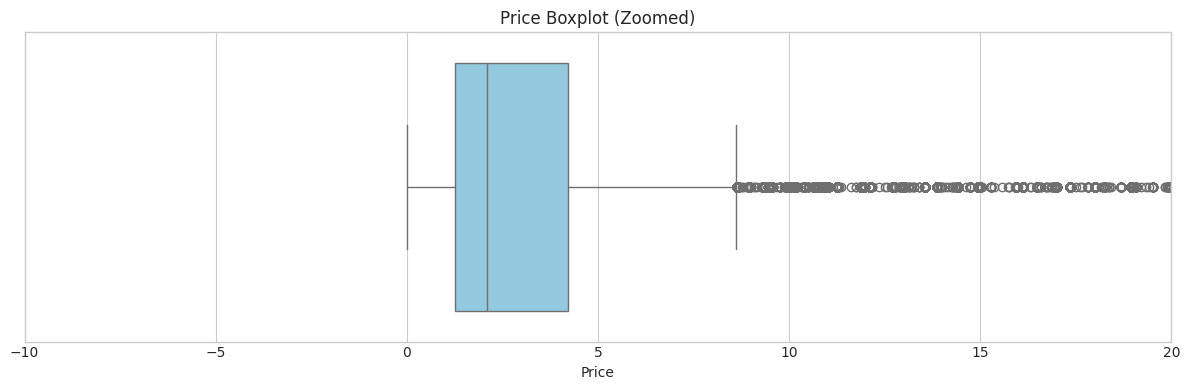

In [21]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    data=df,
    x='Price',
    color='skyblue'
)

plt.xlim(-10, 20)

plt.title('Price Boxplot (Zoomed)')
plt.xlabel('Price')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'price_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

The unit price distribution is concentrated primarily between £1 and £10. A logarithmic x-axis helps display the wide range of positive prices while making the concentration around the lower price range easier to observe.

The positive-price histogram suggests a more balanced distribution after accounting for the logarithmic scale, although this does not by itself establish that prices follow a log-normal distribution.

The boxplot highlights the central price range. The median unit price is approximately £2.10, with the middle 50% of observations ranging from £1.25 to £4.21. Higher-priced observations extend beyond the upper whisker, indicating a long tail of comparatively expensive items.

**Key observations:**
- Most transaction lines have relatively low unit prices.
- The median price is £2.10, while the mean is higher at approximately £4.69.
- A small number of high-priced observations extend well beyond the central distribution.
- Negative prices are associated with administrative adjustments identified in Section 4 and should not be interpreted as ordinary product prices.

#### 5.3 Quantity-Price Relationship

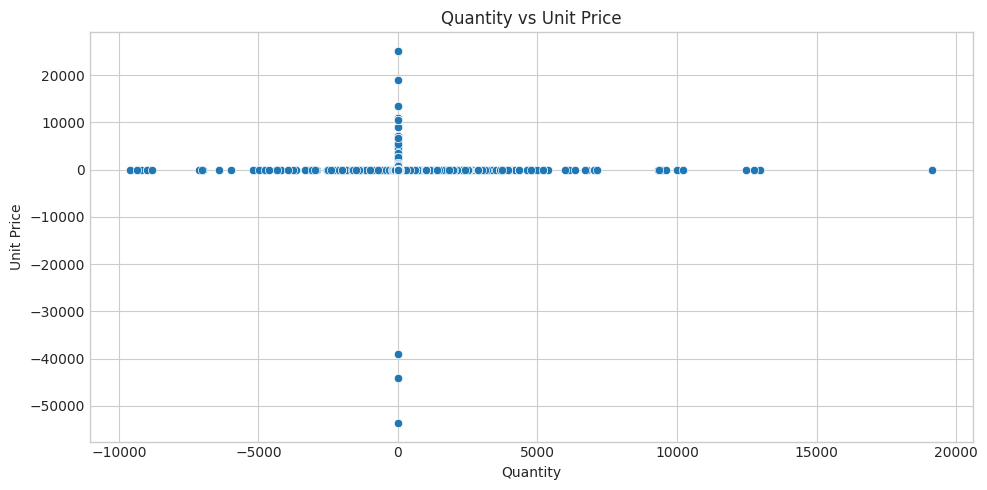

In [22]:
plt.figure(figsize=(10,5))

sns.scatterplot(data=df, x='Quantity', y='Price')

plt.title('Quantity vs Unit Price')
plt.xlabel('Quantity')
plt.ylabel('Unit Price')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'quantity_price_scatter.png', dpi=300, bbox_inches='tight')
plt.show()


The scatterplot examines the relationship between transaction quantity and unit price. The visualization reveals substantial variation in both variables, including negative quantities, unusually large quantities, and extreme price values.

Most observations are concentrated around relatively small quantities and low unit prices. However, several extreme observations extend far beyond this central cluster, making the overall relationship difficult to interpret at the full scale.

Negative quantities are associated with returns or cancellation-related transactions, while the extreme negative price observations correspond to administrative adjustments identified in Section 4. These records require separate consideration when interpreting ordinary purchasing behavior.

Large quantities paired with very low prices and unusually high unit prices also warrant further investigation. Their business meaning should be established by examining the underlying transaction records rather than inferred from the scatterplot alone.

**Key observations:**
- Most transaction lines are concentrated within relatively low quantity and price ranges.
- Extreme observations create substantial variation across both axes.
- Returns, cancellations, and administrative adjustments can influence the apparent relationship.
- Further investigation is needed before using these observations in customer or product performance analysis.

### 6. Duplicate Record Analysis

In [23]:
exact_duplicates = df.duplicated().sum()

print(f"Exact duplicate records: {exact_duplicates:,}")

Exact duplicate records: 6,865


In [24]:
duplicate_checks = {
    'Invoice': ['Invoice'],
    'Invoice + Quantity': ['Invoice', 'Quantity'],
    'Invoice + Quantity + StockCode': ['Invoice', 'Quantity', 'StockCode'],
    'Invoice + Quantity + StockCode + InvoiceDate': ['Invoice', 'Quantity', 'StockCode', 'InvoiceDate'],
    'Invoice + Quantity + StockCode + InvoiceDate + Price': ['Invoice', 'Quantity', 'StockCode', 'InvoiceDate', 'Price'],
}

for label, columns in duplicate_checks.items():
    count = df.duplicated(subset=columns).sum()
    print(f"Duplicate {label} combinations: {count:,}")

Duplicate Invoice combinations: 496,645
Duplicate Invoice + Quantity combinations: 392,643
Duplicate Invoice + Quantity + StockCode combinations: 6,980
Duplicate Invoice + Quantity + StockCode + InvoiceDate combinations: 6,979
Duplicate Invoice + Quantity + StockCode + InvoiceDate + Price combinations: 6,865


In [25]:
duplicate_df = (df[df.duplicated()].sort_values(by=['Invoice', 'StockCode']))

duplicate_df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
390,489517,84951A,S/4 PISTACHIO LOVEBIRD COASTERS,1,2009-12-01 11:34:00,2.55,16329.0,United Kingdom
657,489529,22028,PENNY FARTHING BIRTHDAY CARD,12,2009-12-01 11:51:00,0.42,17984.0,United Kingdom
658,489529,22036,DINOSAUR BIRTHDAY CARD,12,2009-12-01 11:51:00,0.42,17984.0,United Kingdom


In [66]:
line_duplicates = df[df.duplicated(subset=['Invoice', 'Quantity', 'StockCode'],keep=False)].sort_values(by=['Invoice', 'StockCode'])
line_duplicates = (
    df[df.duplicated(
        subset=['Invoice', 'Quantity', 'StockCode'],
        keep=False
    )]
    .sort_values(by=['Invoice', 'StockCode'])
)

line_duplicates.head(20)
line_duplicates[line_duplicates.duplicated(subset=['Invoice', 'Quantity', 'StockCode'], keep=False)].head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


In [67]:
duplicate_columns = ['Invoice', 'Quantity', 'StockCode']

other_columns = [column for column in df.columns if column not in duplicate_columns]

repeated_lines = df[df.duplicated(subset=duplicate_columns, keep=False)].copy()

attribute_variations = (repeated_lines.groupby(duplicate_columns)[other_columns].nunique(dropna=False))

non_identical_groups = attribute_variations[attribute_variations.gt(1).any(axis=1)]

print(f"Non-identical repeated combinations: {len(non_identical_groups):,}")

Non-identical repeated combinations: 90


In [68]:
non_identical_records = (
    repeated_lines
    .set_index(duplicate_columns)
    .loc[non_identical_groups.index]
    .reset_index()
    .sort_values(duplicate_columns)
)

non_identical_records.head(20)

,Invoice,Quantity,StockCode,Description,InvoiceDate,Price,Customer ID,Country
0,489856,5,22111,SCOTTIE DOG HOT WATER BOTTLE,2009-12-02 14:36:00,8.65,NaN,United Kingdom
1,489856,5,22111,SCOTTIE DOG HOT WATER BOTTLE,2009-12-02 14:36:00,11.26,NaN,United Kingdom
2,490300,1,M,Manual,2009-12-04 14:19:00,0.85,12970.0,United Kingdom
3,490300,1,M,Manual,2009-12-04 14:19:00,0.21,12970.0,United Kingdom
4,490741,7,22111,SCOTTIE DOG HOT WATER BOTTLE,2009-12-07 17:56:00,8.65,NaN,United Kingdom
5,490741,7,22111,SCOTTIE DOG HOT WATER BOTTLE,2009-12-07 17:56:00,11.26,NaN,United Kingdom
6,490963,1,20682,RED SPOTTY CHILDS UMBRELLA,2009-12-08 15:49:00,3.24,NaN,United Kingdom
7,490963,1,20682,RED SPOTTY CHILDS UMBRELLA,2009-12-08 15:49:00,6.91,NaN,United Kingdom
8,490963,1,21278,VINTAGE KITCHEN PRINT PUDDINGS,2009-12-08 15:49:00,2.55,NaN,United Kingdom
9,490963,1,21278,VINTAGE KITCHEN PRINT PUDDINGS,2009-12-08 15:49:00,5.17,NaN,United Kingdom


In [69]:
variation_summary = (
    attribute_variations
    .gt(1)
    .sum()
    .sort_values(ascending=False)
)

print("Columns with differing values:")
print(variation_summary[variation_summary > 0])

Columns with differing values:
Price          89
InvoiceDate     1
dtype: int64


In [70]:
group_sizes = non_identical_records.groupby(
    duplicate_columns
).size()

print(f"Distinct non-identical groups: {len(group_sizes):,}")
print(f"Records in these groups: {group_sizes.sum():,}")
print(f"Additional repeated rows: {(group_sizes - 1).sum():,}")

Distinct non-identical groups: 90
Records in these groups: 206
Additional repeated rows: 116


### Findings and Interpretation

The dataset contains 6,865 exact duplicate records. Further investigation identified 90 distinct groups with repeated Invoice, Quantity, and StockCode combinations that differ in at least one other attribute. These groups contain 206 records, representing 116 additional repeated rows beyond the first occurrence in each group.

Price was the differing attribute in 89 of the 90 groups, while one group contained differing InvoiceDate values. This indicates that repeated invoice-line combinations do not necessarily represent exact duplicate transactions.

The findings highlight the importance of distinguishing exact duplicates from records that share transaction identifiers but contain different attributes. Such records may reflect pricing variations, adjustments, or other transaction-level details.

No records are removed at this stage. Exact duplicates and non-identical repeated combinations will be evaluated separately during data cleaning to avoid removing potentially valid transaction information.

### 7. Customer-Level Exploration

#### 7.1 Customer Coverage

In [31]:
unique_customerid = df['Customer ID'].nunique()

print(f"Number of unique customer id: {unique_customerid}")

Number of unique customer id: 4383


In [32]:
customer_id_summary = pd.DataFrame({
    "Records with Missing customers": [df['Customer ID'].isna().sum()],
    "Percentage of missing": [round(df['Customer ID'].isna().mean() * 100, 2)]
})

customer_id_summary

,Records with Missing customers,Percentage of missing
0,107927,20.54


#### 7.2 Purchase Frequency

In [33]:
sales_df = df[
    df['Invoice'].astype(str).str.startswith(('4', '5'))
    & df['Customer ID'].notna()
].copy()

customer_invoices = (
    sales_df.groupby('Customer ID')['Invoice']
    .nunique()
    .reset_index(name='Distinct Invoices')
    .sort_values(by='Distinct Invoices', ascending=False)
)

customer_invoices

,Customer ID,Distinct Invoices
1842,14911.0,205
3998,17850.0,155
251,12748.0,144
2135,15311.0,121
506,13089.0,109
...,...,...
4280,18246.0,1
4284,18253.0,1
4285,18254.0,1
4286,18255.0,1


In [34]:
customer_invoices['Distinct Invoices'].describe()

count    4314.000000
mean        4.454103
std         8.168658
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       205.000000
Name: Distinct Invoices, dtype: float64

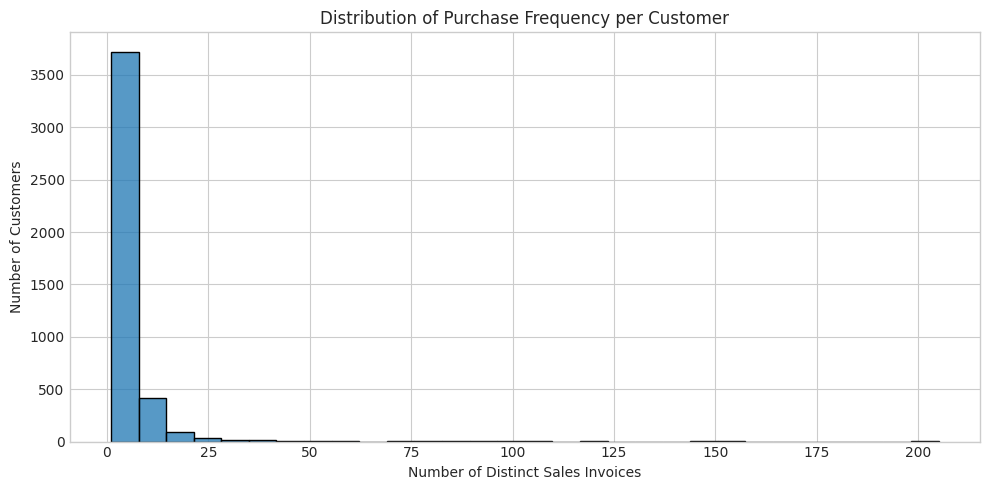

In [35]:
plt.figure(figsize=(10, 5))
sns.histplot(data=customer_invoices, x='Distinct Invoices', bins=30)

plt.title('Distribution of Purchase Frequency per Customer')
plt.xlabel('Number of Distinct Sales Invoices')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'purchase_frequency_distr.png', dpi=300, bbox_inches='tight')
plt.show()

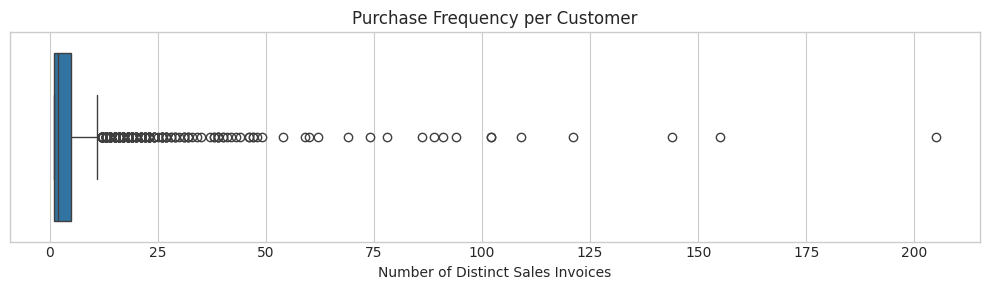

In [36]:
plt.figure(figsize=(10, 3))
sns.boxplot(data=customer_invoices, x='Distinct Invoices')

plt.title('Purchase Frequency per Customer')
plt.xlabel('Number of Distinct Sales Invoices')
plt.tight_layout()
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'customer_purchase_frequency_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

In [37]:
top_frequency_customers = customer_invoices.head(10)

top_frequency_customers

,Customer ID,Distinct Invoices
1842,14911.0,205
3998,17850.0,155
251,12748.0,144
2135,15311.0,121
506,13089.0,109
1607,14606.0,102
1270,14156.0,102
939,13694.0,94
3991,17841.0,91
4185,18102.0,89


#### 7.3 Customer Spending

In [38]:
sales_df['Line Value'] = sales_df['Quantity'] * sales_df['Price']

customer_spending = (
    sales_df.groupby('Customer ID')
    .agg(
        **{
            'Total Spending': ('Line Value', 'sum'),
            'Average Line Value': ('Line Value', 'mean'),
            'Transaction Lines': ('Invoice', 'count'),
            'Distinct Invoices': ('Invoice', 'nunique')
        }
    )
    .reset_index()
    .sort_values('Total Spending', ascending=False)
)

customer_spending

,Customer ID,Total Spending,Average Line Value,Transaction Lines,Distinct Invoices
4185,18102.0,349164.35,556.880941,627,89
1638,14646.0,248396.50,140.020575,1774,78
1270,14156.0,196566.74,74.232153,2648,102
1842,14911.0,152147.57,27.315542,5570,205
939,13694.0,131443.19,137.349206,957,94
...,...,...,...,...,...
2558,15913.0,6.30,6.300000,1,1
1012,13788.0,3.75,3.750000,1,1
1229,14095.0,2.95,2.950000,1,1
1233,14103.0,0.00,0.000000,1,1


In [39]:
customer_spending[
    ['Total Spending', 'Average Line Value']
].describe()

,Total Spending,Average Line Value
count,4314.000000,4314.000000
mean,2047.288659,36.939383
std,8912.523243,217.655486
min,0.000000,0.000000
25%,307.950000,11.107278
50%,705.550000,17.342652
75%,1722.802500,24.803239
max,349164.350000,10953.500000


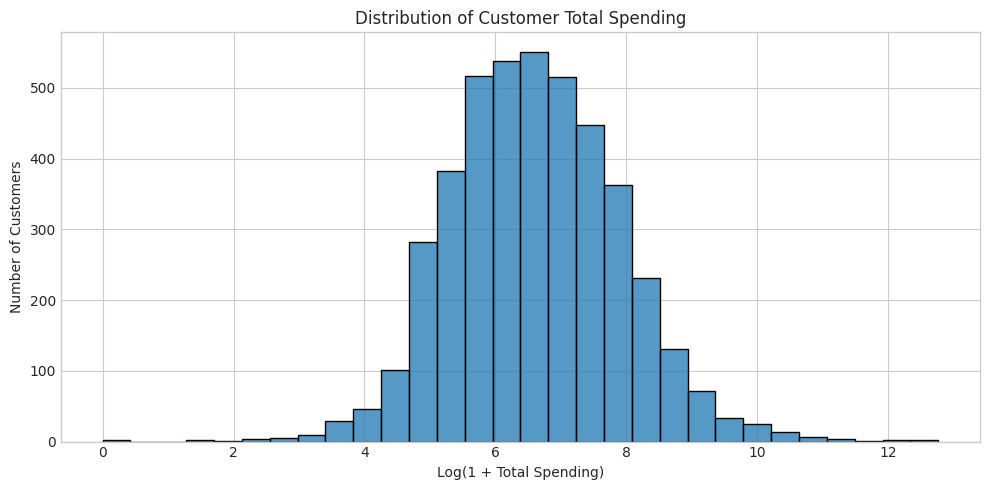

In [40]:
plt.figure(figsize=(10, 5))
sns.histplot(
    x=np.log1p(customer_spending['Total Spending']),
    bins=30
)

plt.title('Distribution of Customer Total Spending')
plt.xlabel('Log(1 + Total Spending)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'customer_spending_distr.png', dpi=300, bbox_inches='tight')
plt.show()

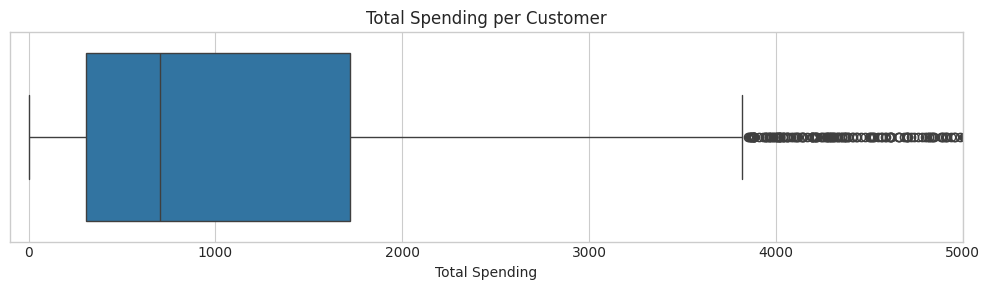

In [41]:
plt.figure(figsize=(10, 3))
sns.boxplot(data=customer_spending, x='Total Spending')

plt.xlim(-100,5000)
plt.title('Total Spending per Customer')
plt.xlabel('Total Spending')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'customer_spending_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

In [42]:
top_spending_customers = (
    customer_spending
    .nlargest(10, 'Total Spending')
)

top_spending_customers

,Customer ID,Total Spending,Average Line Value,Transaction Lines,Distinct Invoices
4185,18102.0,349164.35,556.880941,627,89
1638,14646.0,248396.50,140.020575,1774,78
1270,14156.0,196566.74,74.232153,2648,102
1842,14911.0,152147.57,27.315542,5570,205
939,13694.0,131443.19,137.349206,957,94
3746,17511.0,84541.17,89.178449,948,31
1953,15061.0,83284.38,142.610240,584,86
3130,16684.0,80489.21,182.515215,441,27
3179,16754.0,65500.07,467.857643,140,29
4067,17949.0,60117.60,691.006897,87,74


#### 7.4 Customer Activity

In [43]:
customer_activity = (
    sales_df.groupby('Customer ID')
    .agg(
        **{
            'First Purchase': ('InvoiceDate', 'min'),
            'Last Purchase': ('InvoiceDate', 'max'),
            'Distinct Invoices': ('Invoice', 'nunique')
        }
    )
    .reset_index()
)

customer_activity['Activity Span (Days)'] = (
    customer_activity['Last Purchase'] -
    customer_activity['First Purchase']
).dt.days

In [44]:
customer_activity['Activity Span (Days)'].describe()

count    4314.000000
mean      133.936486
std       132.827714
min         0.000000
25%         0.000000
50%       105.000000
75%       253.750000
max       373.000000
Name: Activity Span (Days), dtype: float64

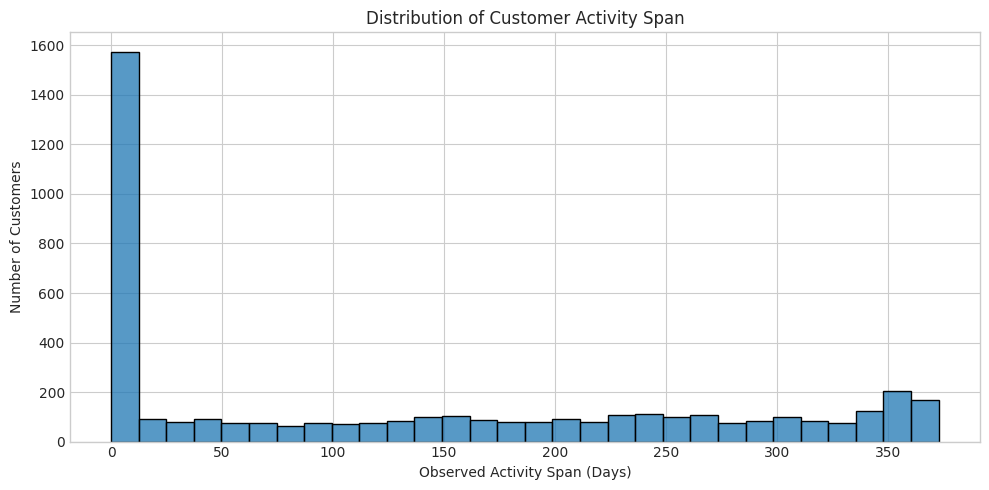

In [45]:
plt.figure(figsize=(10, 5))
sns.histplot(data=customer_activity, x='Activity Span (Days)', bins=30)

plt.title('Distribution of Customer Activity Span')
plt.xlabel('Observed Activity Span (Days)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'customer_activity_span_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

### Findings and Interpretation

The customer-level analysis identified 4,383 unique customers, with 20.54% of transaction records missing Customer IDs. After filtering for identified customers with standard sales invoices, 4,314 customers remained.

Purchase frequency was right-skewed, with a median of 2 invoices per customer and a maximum of 205. Customer spending showed a similar pattern, with median spending of 705.55 GBP compared with a mean of 2,047.29 GBP.

The median observed customer activity span was 105 days, with some customers recording purchases on only one calendar day and others spanning up to 373 days.

Overall, customer purchasing behavior varies considerably, providing a foundation for future customer segmentation and RFM analysis.

### 8. Product Level Exploration

#### 8.1 Product Overview

In [46]:
product_summary = pd.DataFrame({
    'Unique StockCodes': [df['StockCode'].nunique()],
    'Unique Descriptions': [df['Description'].nunique()],
    'Missing Descriptions': [df['Description'].isna().sum()],
    'Missing Description (%)': [round(df['Description'].isna().mean() * 100, 2)]
})

product_summary

,Unique StockCodes,Unique Descriptions,Missing Descriptions,Missing Description (%)
0,4632,4681,2928,0.56


In [47]:
stockcode_descriptions = (
    df.groupby('StockCode')['Description']
    .nunique()
    .reset_index(name='Unique Descriptions')
    .sort_values('Unique Descriptions', ascending=False)
)

stockcode_descriptions.head(15)

,StockCode,Unique Descriptions
1752,22423,6
2047,22734,5
1684,22345,4
256,20685,4
1683,22344,4
971,21523,4
1349,21955,4
1491,22139,4
1685,22346,4
1580,22236,4


In [48]:
multiple_descriptions = stockcode_descriptions[
    stockcode_descriptions['Unique Descriptions'] > 1
]

multiple_description_details = (
    df[df['StockCode'].isin(multiple_descriptions['StockCode'])]
    [['StockCode', 'Description']]
    .drop_duplicates()
    .sort_values(['StockCode', 'Description'])
)

multiple_description_details.head(30)

,StockCode,Description
2944,10120,DOGGY RUBBER
194372,10120,Zebra invcing error
614,15056N,EDWARDIAN PARASOL NATURAL
100429,15056N,wedding co returns?
461044,15058B,PINK POLKADOT GARDEN PARASOL
54894,15058B,PINK WHITE SPOTS GARDEN PARASOL
10462,16011,ANIMAL STICKERS
119710,16011,ANIMAL STICKERS
314800,16012,FOOD/DRINK SPONGE STICKERS
4157,16012,FOOD/DRINK SPUNGE STICKERS


In [49]:
description_consistency = pd.Series({
    'Total StockCodes': df['StockCode'].nunique(),
    'StockCodes with Multiple Descriptions': (
        stockcode_descriptions['Unique Descriptions'] > 1
    ).sum(),
    'StockCodes with One Description': (
        stockcode_descriptions['Unique Descriptions'] == 1
    ).sum()
})

description_consistency

Total StockCodes                         4632
StockCodes with Multiple Descriptions     687
StockCodes with One Description          3589
dtype: int64

#### 8.2 Product Purchase Frequency

In [50]:
product_sales_df = df[
    df['Invoice'].astype(str).str.startswith(('4', '5'))
    & df['Description'].notna()
].copy()

product_descriptions = (
    product_sales_df.groupby(['StockCode', 'Description'])
    .size()
    .reset_index(name='Description Count')
    .sort_values('Description Count', ascending=False)
    .drop_duplicates(subset='StockCode')
    [['StockCode', 'Description']]
)

product_frequency = (
    product_sales_df.groupby('StockCode')
    .agg(
        **{
            'Transaction Lines': ('Invoice', 'size'),
            'Distinct Invoices': ('Invoice', 'nunique')
        }
    )
    .reset_index()
    .merge(product_descriptions, on='StockCode', how='left')
    .sort_values('Distinct Invoices', ascending=False)
)

In [51]:
top_products_frequency = (
    product_frequency
    [['StockCode', 'Description', 'Distinct Invoices', 'Transaction Lines']]
    .head(10)
)

top_products_frequency

,StockCode,Description,Distinct Invoices,Transaction Lines
3652,85123A,WHITE HANGING HEART T-LIGHT HOLDER,3283,3423
1638,22423,REGENCY CAKESTAND 3 TIER,2028,2054
3624,85099B,JUMBO BAG RED RETROSPOT,1969,2015
614,21212,PACK OF 72 RETRO SPOT CAKE CASES,1853,1920
631,21232,STRAWBERRY CERAMIC TRINKET BOX,1640,1714
256,20725,LUNCH BAG RED SPOTTY,1539,1584
3348,84879,ASSORTED COLOUR BIRD ORNAMENT,1414,1451
3483,84991,60 TEATIME FAIRY CAKE CASES,1336,1394
1074,21754,HOME BUILDING BLOCK WORD,1331,1376
399,20914,SET/5 RED SPOTTY LID GLASS BOWLS,1184,1223


#### 8.3 Product Sales Performance

In [52]:
# Calculate product-level quantity and transaction value
product_sales = (
    product_sales_df.assign(
        Line_Value=product_sales_df['Quantity'] * product_sales_df['Price']
    )
    .groupby('StockCode')
    .agg(
        **{
            'Total Quantity': ('Quantity', 'sum'),
            'Total Transaction Value': ('Line_Value', 'sum')
        }
    )
    .reset_index()
    .merge(product_descriptions, on='StockCode', how='left')
)

product_sales

,StockCode,Total Quantity,Total Transaction Value,Description
0,10002,7976,6338.01,INFLATABLE POLITICAL GLOBE
1,10002R,4,20.57,ROBOT PENCIL SHARPNER
2,10080,12,10.20,GROOVY CACTUS INFLATABLE
3,10109,4,1.68,BENDY COLOUR PENCILS
4,10120,-8513,105.57,DOGGY RUBBER
...,...,...,...,...
4257,gift_0001_40,2,65.39,Dotcomgiftshop Gift Voucher £40.00
4258,gift_0001_50,2,86.03,Dotcomgiftshop Gift Voucher £50.00
4259,gift_0001_70,1,59.57,Dotcomgiftshop Gift Voucher £70.00
4260,gift_0001_80,1,69.56,Dotcomgiftshop Gift Voucher £80.00


In [53]:
top_products_quantity = (
    product_sales
    .nlargest(10, 'Total Quantity')
    [['StockCode', 'Description', 'Total Quantity']]
)

top_products_quantity

,StockCode,Description,Total Quantity
614,21212,PACK OF 72 RETRO SPOT CAKE CASES,60141
3652,85123A,WHITE HANGING HEART T-LIGHT HOLDER,58296
2904,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55202
3624,85099B,JUMBO BAG RED RETROSPOT,48478
114,17003,BROCADE RING PURSE,48384
3348,84879,ASSORTED COLOUR BIRD ORNAMENT,44915
3483,84991,60 TEATIME FAIRY CAKE CASES,36502
1433,22197,SMALL POPCORN HOLDER,33013
1246,21977,PACK OF 60 PINK PAISLEY CAKE CASES,31940
631,21232,STRAWBERRY CERAMIC TRINKET BOX,27128


In [54]:
top_products_value = (
    product_sales
    .nlargest(10, 'Total Transaction Value')
    [['StockCode', 'Description', 'Total Transaction Value']]
)

top_products_value

,StockCode,Description,Total Transaction Value
4247,M,Manual,262606.01
1638,22423,REGENCY CAKESTAND 3 TIER,170078.51
3652,85123A,WHITE HANGING HEART T-LIGHT HOLDER,158590.87
4246,DOT,DOTCOM POSTAGE,116408.71
3624,85099B,JUMBO BAG RED RETROSPOT,89114.78
3348,84879,ASSORTED COLOUR BIRD ORNAMENT,73092.99
1325,22086,PAPER CHAIN KIT 50'S CHRISTMAS,58189.25
2517,47566,PARTY BUNTING,49682.72
4249,POST,POSTAGE,49477.54
2956,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,47985.09


#### 8.4 Product Level Distribution

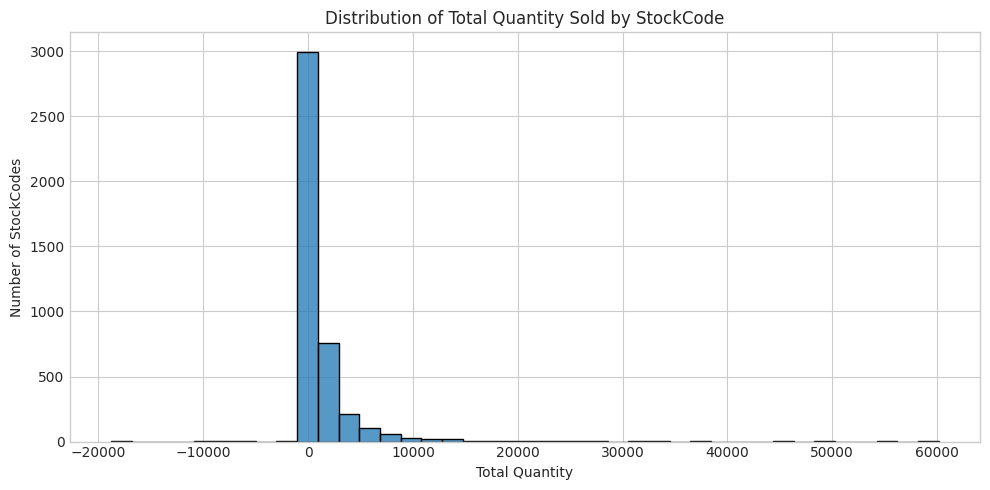

In [55]:
plt.figure(figsize=(10, 5))
sns.histplot(data=product_sales, x='Total Quantity', bins=40)

plt.title('Distribution of Total Quantity Sold by StockCode')
plt.xlabel('Total Quantity')
plt.ylabel('Number of StockCodes')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'product_quantity_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

### Findings and Interpretation

The product-level analysis identified 4,632 unique StockCodes, with inconsistencies in product descriptions across some codes. The most frequently purchased item by distinct invoices was the White Hanging Heart T-Light Holder, appearing in 3,283 invoices.

The highest aggregate quantities were recorded for products such as Pack of 72 Retro Spot Cake Cases and White Hanging Heart T-Light Holder. However, the highest transaction values also included non-merchandise entries such as Manual and Postage, which should be distinguished from physical products.

Overall, product activity was strongly right-skewed, with most StockCodes recording relatively low net quantities and a small number showing much higher totals. Negative net quantities and inconsistent descriptions highlight the need for further validation during data cleaning.

### 9. Geographic Exploration

#### 9.1 Country Coverage

In [59]:
country_summary = pd.DataFrame({
    'Unique Countries': [df['Country'].nunique()],
    'Missing Country Records': [df['Country'].isna().sum()],
    'Missing Country (%)': [round(df['Country'].isna().mean() * 100, 2)]
})

display(country_summary)

country_frequency = (
    df['Country']
    .value_counts(dropna=False)
    .reset_index()
)

country_frequency.columns = ['Country', 'Transaction Records']
display(country_frequency)

,Unique Countries,Missing Country Records,Missing Country (%)
0,40,0,0.0


,Country,Transaction Records
0,United Kingdom,485852
1,EIRE,9670
2,Germany,8129
3,France,5772
4,Netherlands,2769
5,Spain,1278
6,Switzerland,1187
7,Portugal,1101
8,Belgium,1054
9,Channel Islands,906


#### 9.2 Transaction Distribution by Country

In [60]:
country_transactions = (
    df.groupby('Country')
    .agg(
        **{
            'Distinct Invoices': ('Invoice', 'nunique'),
            'Transaction Lines': ('Invoice', 'count')
        }
    )
    .reset_index()
    .sort_values('Distinct Invoices', ascending=False)
)

display(country_transactions)

,Country,Distinct Invoices,Transaction Lines
37,United Kingdom,26633,485852
13,Germany,513,8129
10,EIRE,457,9670
12,France,297,5772
24,Netherlands,150,2769
31,Spain,85,1278
32,Sweden,83,902
3,Belgium,65,1054
28,Portugal,57,1101
33,Switzerland,50,1187


#### 9.3 Sales Performance by Country


In [61]:
country_sales_df = df[
    df['Invoice'].astype(str).str.startswith(('4', '5'))
    & df['Country'].notna()
].copy()

country_sales = (
    country_sales_df.assign(
        Line_Value=country_sales_df['Quantity'] * country_sales_df['Price']
    )
    .groupby('Country')
    .agg(
        **{
            'Total Quantity': ('Quantity', 'sum'),
            'Total Transaction Value': ('Line_Value', 'sum'),
            'Distinct Invoices': ('Invoice', 'nunique')
        }
    )
    .reset_index()
    .sort_values('Total Transaction Value', ascending=False)
)

display(country_sales)

,Country,Total Quantity,Total Transaction Value,Distinct Invoices
37,United Kingdom,4534289,8845755.693,22560
10,EIRE,193117,380977.820,348
24,Netherlands,183680,268786.000,135
13,Germany,108740,202395.321,347
12,France,163183,147211.490,241
32,Sweden,52567,53525.390,69
9,Denmark,229690,50906.850,26
31,Spain,22856,47601.420,66
33,Switzerland,22255,43921.390,40
0,Australia,20189,31446.800,40


### Findings and Interpretation

The geographic analysis identified 40 countries, with no missing Country values. The United Kingdom accounted for approximately 92.46% of all transaction records, demonstrating the dataset's strong geographic concentration.

The UK also dominated transaction activity, recording 26,633 distinct invoices across all invoice types. Among standard sales invoices, it generated approximately £8.85 million in transaction value. EIRE, the Netherlands, and Germany were the next largest markets by transaction value.

Differences between countries in transaction volume, net quantity, and transaction value indicate varying purchasing patterns. These results provide a geographic overview of the retailer's sales activity, while further cleaning is needed before drawing conclusions about finalized revenue or market performance.

### 10. Data Quality Assessment

#### 10.1 Identified Data Quality Issues

In [71]:
data_quality_summary = pd.DataFrame({
    'Issue': [
        'Missing Customer IDs',
        'Missing Product Descriptions',
        'Exact Duplicate Records',
        'Non-identical Repeated Combinations',
        'Negative Quantity Records',
        'Zero Price Records',
        'Negative Price Records',
        'StockCodes with Multiple Descriptions'
    ],
    'Count': [
        df['Customer ID'].isna().sum(),
        df['Description'].isna().sum(),
        df.duplicated().sum(),
        len(non_identical_groups),
        (df['Quantity'] < 0).sum(),
        (df['Price'] == 0).sum(),
        (df['Price'] < 0).sum(),
        (stockcode_descriptions['Unique Descriptions'] > 1).sum()
    ]
})

data_quality_summary['Percentage'] = (
    data_quality_summary['Count'] / len(df) * 100
).round(2)

display(data_quality_summary)

,Issue,Count,Percentage
0,Missing Customer IDs,107927,20.54
1,Missing Product Descriptions,2928,0.56
2,Exact Duplicate Records,6865,1.31
3,Non-identical Repeated Combinations,90,0.02
4,Negative Quantity Records,12326,2.35
5,Zero Price Records,3687,0.70
6,Negative Price Records,3,0.00
7,StockCodes with Multiple Descriptions,687,0.13


#### 10.2 Data Cleaning Priorities

In [73]:
cleaning_priorities = pd.DataFrame({
    'Area': [
        'Missing Values',
        'Transaction Records',
        'Duplicate Records',
        'Product Information',
        'Data Types',
        'Feature Engineering'
    ],
    'Planned Action': [
        'Evaluate missing Customer IDs and product descriptions.',
        'Review cancellations, returns, and administrative adjustments.',
        'Validate exact duplicates before deciding whether to remove them.',
        'Review inconsistent descriptions and non-merchandise StockCodes.',
        'Standardize dates, identifiers, and numeric fields.',
        'Construct transaction value and customer-level analytical variables.'
    ]
})

display(cleaning_priorities)

,Area,Planned Action
0,Missing Values,Evaluate missing Customer IDs and product desc...
1,Transaction Records,"Review cancellations, returns, and administrat..."
2,Duplicate Records,Validate exact duplicates before deciding whet...
3,Product Information,Review inconsistent descriptions and non-merch...
4,Data Types,"Standardize dates, identifiers, and numeric fi..."
5,Feature Engineering,Construct transaction value and customer-level...


### 11. EDA SUMMARY

### Key Findings

The exploratory analysis examined transaction patterns, customer purchasing behavior, product performance, and geographic distribution within the Online Retail II dataset.

Key findings include:

- The dataset contains 525,461 transaction records across 40 countries.
- Transaction activity is heavily concentrated in the United Kingdom.
- Customer purchasing frequency and spending are strongly right-skewed, with substantial variation across customers.
- A relatively small number of products account for high transaction quantities and values.
- Product descriptions and transaction records contain inconsistencies that require further validation.
- Missing customer identifiers, duplicate records, returns, and administrative adjustments are important considerations for subsequent analysis.

The EDA revealed useful patterns in customer and product activity while identifying data quality issues that must be addressed before drawing final business conclusions.
